# MaxCut — QUBO + Simulated Annealing

MaxCut como Ising/QUBO (Farhi / demo PennyLane):
$C = \sum_{(j,k)\in E}\tfrac12(1-Z_j Z_k)$. Maximizar $C$ ≡ minimizar $-C$.

SA clásico sobre flips de bits (mismo paisaje que QAOA/VQE).


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


In [2]:
def resolve_maxcut_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "MaxCutOptimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization" / "MaxCutOptimization"


MAXCUT_DIR = resolve_maxcut_dir()
INSTANCE_PATH = MAXCUT_DIR / "instance" / "hamlib_maxcut.json"
METRICS_DIR = MAXCUT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

instance = json.loads(INSTANCE_PATH.read_text())
n = int(instance["n"])
edges = [tuple(e) for e in instance["edges"]]
OPTIMAL_CUT = int(instance["optimal_cut"])
OPTIMAL_BITS = list(instance["optimal_bits"])
nodes = list(range(n))

print(
    f"HamLib MaxCut | index={instance['hamlib_index']} id={instance['hamlib_id']} "
    f"n={n} |E|={len(edges)} optimal_cut={OPTIMAL_CUT}"
)
print("Fuente:", instance["url"])
print("Demo QAOA:", instance["demo_ref"])


def cut_value(bits) -> int:
    return int(sum(1 for a, b in edges if bits[a] != bits[b]))


def is_success(bits) -> bool:
    return cut_value(bits) == OPTIMAL_CUT


def save_maxcut_metrics(payload: dict, filename: str):
    path = METRICS_DIR / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


HamLib MaxCut | index=8 id=circ_offsets-1-2 n=6 |E|=12 optimal_cut=8
Fuente: https://pennylane.ai/datasets/hamlib-maxcut
Demo QAOA: https://pennylane.ai/demos/tutorial_qaoa_maxcut


## Simulated Annealing


In [3]:
N_RUNS = 20
MAX_ITER = 4000
T0 = 5.0
COOLING = 0.995

def energy_min(bits):
    """Minimizar -cut (= maximizar cut)."""
    return -cut_value(bits)

def sa_maxcut(seed=0, max_iter=MAX_ITER, T0=T0, cooling=COOLING):
    random.seed(seed)
    bits = [random.randint(0, 1) for _ in range(n)]
    e = energy_min(bits)
    best_bits, best_e = bits[:], e
    T = T0
    evals = 0
    for _ in range(max_iter):
        v = random.randrange(n)
        bits[v] ^= 1
        e2 = energy_min(bits)
        evals += 1
        de = e2 - e
        if de <= 0 or random.random() < math.exp(-de / max(T, 1e-12)):
            e = e2
            if e < best_e:
                best_e, best_bits = e, bits[:]
        else:
            bits[v] ^= 1
        T *= cooling
    return best_bits, evals

rows = []
for seed in range(N_RUNS):
    t0 = time.perf_counter()
    bits, evals = sa_maxcut(seed=seed)
    elapsed = time.perf_counter() - t0
    c = cut_value(bits)
    success = is_success(bits)
    rows.append({
        "seed": seed,
        "bits": bits,
        "cut": float(c),
        "success": bool(success),
        "time_s": float(elapsed),
        "energy_evals": evals,
    })
    print(f"seed={seed:02d} success={success} cut={c} time={elapsed:.3f}s")

cuts = np.array([r["cut"] for r in rows], dtype=float)
success_rate = float(np.mean([r["success"] for r in rows]))
times = np.array([r["time_s"] for r in rows], dtype=float)
print(f"success_rate={success_rate:.3f}")

payload = {
    "problem": "maxcut",
    "solver": "simulated_annealing",
    "family": "classical",
    "protocol": {
        "success_max_size": None,
        "n_runs": N_RUNS,
        "max_iter": MAX_ITER,
        "T0": T0,
        "cooling": COOLING,
        "sense": "maximize_cut",
        "hamlib_index": instance["hamlib_index"],
        "hamlib_id": instance["hamlib_id"],
    },
    "instance": {"n": n, "edges": [list(e) for e in edges], "source": instance["source"]},
    "quality": {
        "optimal_cost": float(OPTIMAL_CUT),
        "optimal_bits": OPTIMAL_BITS,
        "cost_mean": float(np.mean(cuts)),
        "cost_best": float(np.max(cuts)),
        "gap_mean": float(np.mean(OPTIMAL_CUT - cuts)),
    },
    "success_rate": success_rate,
    "time_s": {"mean": float(np.mean(times)), "std": float(np.std(times)), "total": float(np.sum(times))},
    "effort": {"energy_evals_mean": float(np.mean([r["energy_evals"] for r in rows]))},
    "runs": rows,
}
# clean None
payload["protocol"].pop("success_max_size", None)
save_maxcut_metrics(payload, "sa_maxcut.json")


seed=00 success=True cut=8 time=0.003s
seed=01 success=True cut=8 time=0.004s
seed=02 success=True cut=8 time=0.004s
seed=03 success=True cut=8 time=0.003s
seed=04 success=True cut=8 time=0.003s
seed=05 success=True cut=8 time=0.003s
seed=06 success=True cut=8 time=0.003s
seed=07 success=True cut=8 time=0.003s
seed=08 success=True cut=8 time=0.003s
seed=09 success=True cut=8 time=0.003s
seed=10 success=True cut=8 time=0.003s
seed=11 success=True cut=8 time=0.003s
seed=12 success=True cut=8 time=0.003s
seed=13 success=True cut=8 time=0.003s
seed=14 success=True cut=8 time=0.003s
seed=15 success=True cut=8 time=0.003s
seed=16 success=True cut=8 time=0.003s
seed=17 success=True cut=8 time=0.003s
seed=18 success=True cut=8 time=0.003s
seed=19 success=True cut=8 time=0.003s
success_rate=1.000
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/sa_maxcut.json


PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/sa_maxcut.json')

## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/instance_maxcut_graph.png


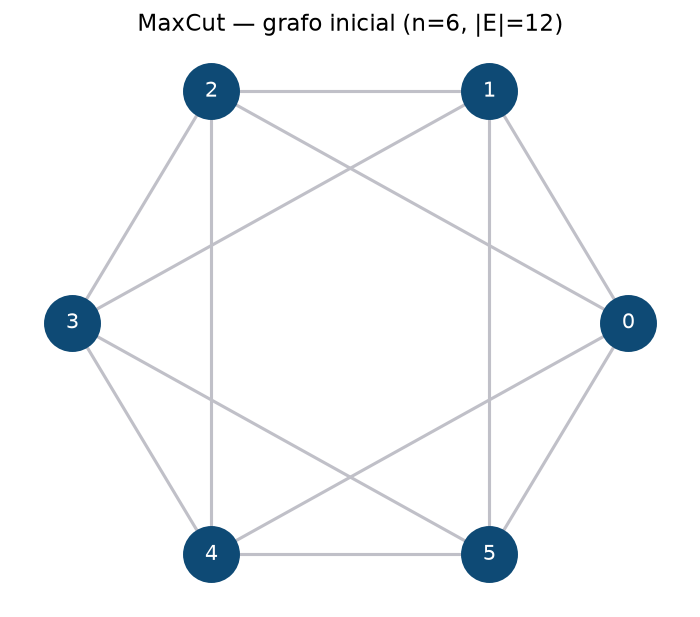

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/sa_maxcut_cut.png


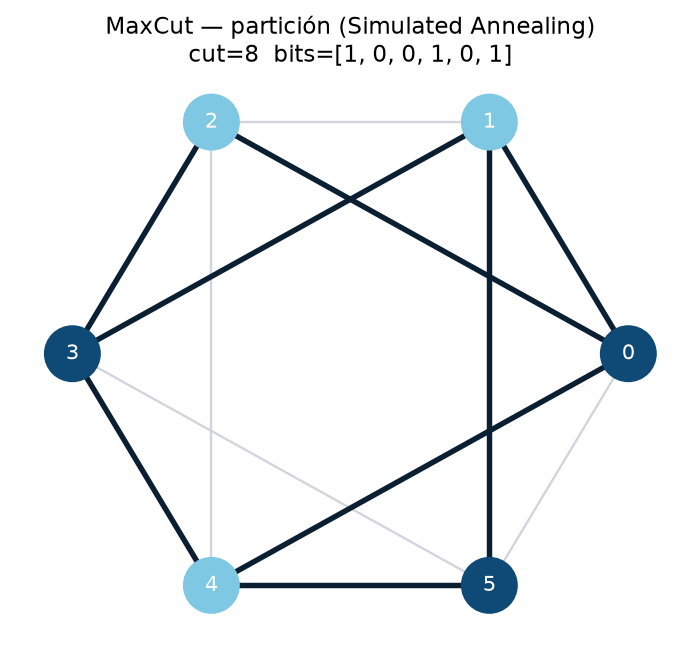

In [4]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_maxcut_instance, plot_maxcut_partition,
)

figures_dir = resolve_figures_dir("Optimization", "MaxCutOptimization")
plot_maxcut_instance(n, edges, figures_dir, stem="instance")
_bits = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("bits") is not None]
    if _runs:
        # MaxCut: higher cut is better
        _bits = max(_runs, key=lambda r: float(r.get("cut", r.get("cost", -1e18)))).get("bits")
if _bits is None and "best_b" in globals() and best_b is not None:
    _bits = best_b
if _bits is None and "bits" in globals() and isinstance(bits, (list, tuple)):
    _bits = bits
if _bits is None and "OPTIMAL_BITS" in globals():
    _bits = OPTIMAL_BITS
if _bits is None:
    raise RuntimeError("No MaxCut bits found for storytelling plot")
plot_maxcut_partition(n, edges, _bits, figures_dir, stem="sa", title="Simulated Annealing")

plt.show()
